# 55 · DQN: replay와 고정 타깃을 신경망에 연결하기

📎 **이번 질문** · Q 표를 신경망으로 바꾸면 어떤 값은 미분하고 어떤 값은 고정해야 할까요?

54번의 안전·위험 배달 경로를 같은 숫자로 다시 만듭니다. 선택한 행동의 Q만 손실에 넣고, 저장한 전이를 재사용하며, 별도 타깃 네트워크의 값을 주기적으로 복사합니다. 실제 NumPy 신경망을 학습하고 정확한 작은 환경 값과 대조합니다.

- 준비물: [03 MLP](../00_기초/03_perceptron_to_mlp.ipynb), [04 optimizer](../00_기초/04_optimizers.ipynb), [13 계산 그래프](../02_연결/13_autodiff.ipynb), [54 SARSA·Q-learning](54_sarsa_q_learning.ipynb). 모든 구현은 이 노트북에 있습니다.
- 도착점: Q 신경망·전체 backward, replay, semi-gradient·고정 타깃, Double DQN, 실제 상호작용과 평가를 연결합니다.
- 학습 모델은 one-hot 4→tanh 16→Q 2, 총114개 파라미터입니다. 원 DQN의 Atari·CNN·전처리·RMSProp 실험을 재현하는 단원이 아닙니다. 작은 MLP·제곱 손실·Adam을 씁니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 수식·구현 | 미분할 배열과 고정할 배열을 표시합니다 |
| 🔍 확인 | 그림·검산 | 정확 미분과 학습 관측을 구분합니다 |
| 📎 참고 | 용어·코드 | 새 축과 규약을 확인합니다 |
| ✏️ 연습 | 한두 줄 구현 | 작은 독립 답과 비교합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. Q의 모든 행동 출력을 계산하지만, 배치의 각 행에서 선택한 행동 값만 TD 손실에 들어갑니다.
2. 고정 y를 향해 현재 Q를 미분합니다. 타깃 네트워크는 optimizer가 아니라 정한 복사 시점에 바뀝니다.
3. Double은 다음 행동 선택과 그 행동의 값 평가를 나눕니다. 어느 작은 실험에서나 성능이 더 좋다는 보장은 아닙니다.

| 기호 | shape | 뜻 |
|---|---|---|
| X,H,Q | `(B,D),(B,H),(B,A)` | replay 배치 상태·은닉값·행동별 Q |
| W1,b1,W2,b2 | `(D,H),(H,),(H,A),(A,)` | 학습하는 네 배열 |
| actions,y | `(B,),(B,)` | 실제 선택 행동·고정한 TD 타깃 |
| θ,θ̄ | 같은 네 배열 | online·별도 복사본 target 파라미터 |

[전체 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/dqn_plots.py)

In [1]:
# 준비 셀: NumPy 계산·그림·연습 검사 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots, run_check
from src.utils.dqn_plots import (
    plot_q_network, plot_td_batch, plot_target_freeze, plot_double_selection,
    plot_dqn_protocol, plot_dqn_learning, plot_dqn_final,
)
setup_plots()
print('NumPy MLP · 고정 타깃 미분 · 실제 replay 학습')

NumPy MLP · 고정 타깃 미분 · 실제 replay 학습


## 🔑 1. 상태에서 행동별 Q를 한 번에 계산합니다

**이 절에서 가져갈 것:** Q 신경망의 출력 열은 행동이고, 행동 번호로 배치마다 한 값을 선택합니다.

위험 경로와 안전 경로의 가치를 한 신경망으로 추정합니다. 54번 환경은 시작0에서 행동0이면 안전2, 행동1이면 위험1로 갑니다. 즉시 보상은0입니다. 안전 상태의 두 행동은 모두 .7, 위험 상태는 행동0이2·행동1이−14를 받고 종료3으로 갑니다. 항상 두 전이 뒤 종료하고 γ=.9입니다.

> **용어**
>
> - **Q-network**는 상태를 넣으면 각 행동의 가치 추정 벡터를 반환하는 신경망입니다. 출력은 확률이 아니어서 음수나1보다 큰 값도 가능합니다.
> - **one-hot 상태**는 상태 번호의 위치만1이고 나머지0인 벡터입니다. 여기서는 `np.eye(4)[state]`로 만듭니다.
> - **online 네트워크 θ**는 실제 손실 기울기로 갱신하는 현재 모델입니다.

$$H=\tanh(XW_1+b_1),\quad Q=HW_2+b_2,\quad q_i=Q_{i,a_i}.$$

손계산 그림은 더 작은 D=3·H=2·A=2를 씁니다. tanh는 원소별로 적용하며, 선택 행동 `a=(0,1)`이면 첫 행0열과 둘째 행1열을 읽습니다.

> **코드** · `Q[np.arange(B),actions]`는 행 번호와 행동 번호를 짝지어 B개를 고릅니다. `@`는 행렬 곱이고 `params['W1']`은 이름으로 가중치 배열을 꺼냅니다.

In [2]:
small_x = np.array([[1.,0.,0.],[0.,1.,0.]])
small_params = {'W1':np.array([[.5,-.2],[.1,.3],[-.4,.2]]),'b1':np.array([.1,-.1]),
                'W2':np.array([[1.,-1.],[.5,.2]]),'b2':np.array([.2,-.3])}
small_actions = np.array([0,1])
small_hidden = np.tanh(small_x@small_params['W1']+small_params['b1'])
small_q = small_hidden@small_params['W2']+small_params['b2']
small_selected = small_q[np.arange(2),small_actions]
loop_q = np.zeros((2,2))
for row in range(2):
    for action in range(2):
        loop_q[row,action] = small_params['b2'][action]
        for unit in range(2):
            loop_q[row,action] += small_hidden[row,unit]*small_params['W2'][unit,action]

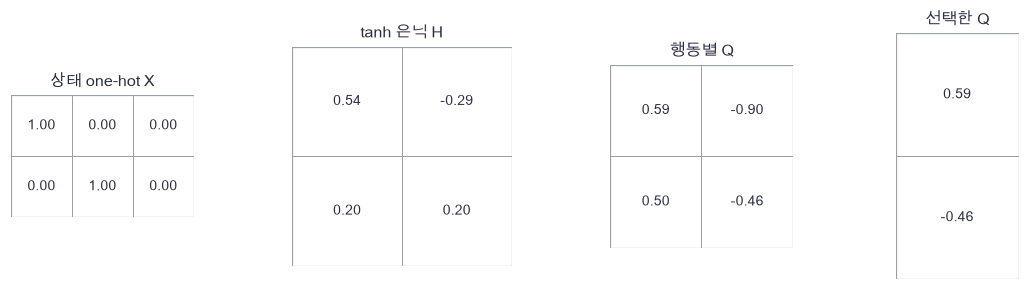

In [3]:
plot_q_network(small_x, small_hidden, small_q, small_selected)

🔍 **확인** · 마지막 열 벡터는 각 행에서 한 행동만 고른 결과입니다. 학습 중 다른 행동의 현재 출력에는 직접 TD 손실을 주지 않지만, 공유 가중치가 바뀌면 다른 상태·행동의 출력도 함께 달라질 수 있습니다.

In [4]:
def make_dqn_environment():
    """54번과 같은 두 전이 환경. next,reward:(4,2), terminal:(4,)."""
    next_state = np.array([[2,1],[3,3],[3,3],[3,3]])
    reward = np.array([[0.,0.],[2.,-14.],[.7,.7],[0.,0.]])
    terminal = np.array([False,False,False,True])
    return next_state,reward,terminal

In [5]:
def init_q_network(rng,input_dim=4,hidden=16,actions=2):
    """one-hot 입력을 tanh 은닉층과 선형 Q로 잇는 4배열 파라미터를 만듭니다."""
    return {'W1':rng.normal(0,0.4,(input_dim,hidden)), 'b1':np.zeros(hidden),
            'W2':rng.normal(0,0.2,(hidden,actions)), 'b2':np.zeros(actions)}

In [6]:
def q_forward(x,params):
    """X:(B,D) → H:(B,H) → Q:(B,A), backward용 cache=(X,H)."""
    hidden = np.tanh(x@params['W1']+params['b1'])
    q = hidden@params['W2']+params['b2']
    return q,(x,hidden)

In [7]:
# 쓰는 것: loop_q, small_hidden, small_params, small_q, small_x (위 절의 정의·실행 셀)
np.testing.assert_allclose(q_forward(small_x,small_params)[0],loop_q)  # 검산: 핵심 forward=행동별 반복문
np.testing.assert_allclose(small_q,loop_q)  # 검산: 벡터화=반복문
np.testing.assert_allclose(small_hidden[0],np.tanh([.6,-.3]))  # 검산: 첫 one-hot 행은 첫 W행+b
next_state,reward,terminal = make_dqn_environment()
assert next_state[0,0]==2 and next_state[0,1]==1, '시작의 두 경로는 안전2·위험1이어야 합니다'
print('Q 출력·행동 선택·환경 경로 통과')

Q 출력·행동 선택·환경 경로 통과


### ✏️ 연습 1 · 각 행에서 선택한 Q

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

actions에 맞는 열 하나씩을 반환하세요.

In [8]:
def exercise_chosen(q, actions):
    """각 행에서 선택한 Q의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return selected

In [9]:
def check_chosen(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([[1.,2.],[3.,4.]]),np.array([1,0])),[2.,3.])  # 검산:첫행1열·둘째행0열
    print('선택 Q 통과')

run_check(check_chosen,exercise_chosen,hint='행과 행동 번호를 짝지어 고릅니다.')

☐ exercise_chosen: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 행과 행동 번호를 짝지어 고릅니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
selected = q[np.arange(len(q)), actions]
```

</details>

## 🔑 2. replay 배치의 고정 타깃을 향해 미분합니다

**이 절에서 가져갈 것:** replay에서 뽑은 전이와 y를 고정하면, 현재 Q만 미분하는 작은 회귀 문제가 됩니다.

이미 경험한 배달 전이 `(s,a,r,s′,terminated)`를 저장하고 다시 뽑습니다. 현재 Q가 바뀌어도 저장한 보상은 그대로입니다. 아래의 y는 먼저 계산해 복사한 숫자로 취급합니다.

> **용어**
>
> - **experience replay**는 실제 경험 전이를 저장하고 배치를 다시 뽑아 학습하는 방식입니다. 이번에는 용량256·균등 복원 추출입니다.
> - **semi-gradient**는 bootstrap 타깃까지 함께 미분하지 않고 현재 예측 쪽만 미분하는 갱신입니다. 고정된 y에 대한 회귀 손실의 미분은 정확하게 계산합니다.
> - **TD loss**는 선택한 Q와 고정 타깃 사이 제곱 오차입니다. 여기서는 미분을 읽기 쉽게 1/2를 곱합니다.

$$L=\frac1{2B}\sum_i(Q_{i,a_i}-y_i)^2,\qquad
\frac{\partial L}{\partial Q_{i,a}}=\frac{Q_{i,a_i}-y_i}{B}\mathbf1[a=a_i].$$
$$dZ=(dQW_2^T)\odot(1-H^2),\quad dW_2=H^TdQ,\quad db_2=\sum_i dQ_i,$$
$$dW_1=X^TdZ,\quad db_1=\sum_i dZ_i,\quad dX=dZW_1^T.$$

합은 배치 축을 없앱니다. 중심차분에서도 y를 다시 계산하면 다른 목적을 미분하므로, 이번 검산은 **같은 고정 y**를 사용합니다. 버퍼에서 뽑는 인덱스는 현재 버퍼 조건부로 독립 복원 추출하지만, 버퍼의 원래 경험들이 통계적으로 독립이 된다는 뜻은 아닙니다.

> **코드** · `np.ndindex(shape)`는 배열의 모든 위치를 순회합니다. `dict.items()`는 이름·배열을 함께 꺼냅니다. `buffer[position]=...`는 오래된 전이를 덮고 `% capacity`는 저장 위치를 처음으로 되돌립니다. `[buffer[i] for i in indices]`는 뽑힌 전이들을 모읍니다.

> **코드** · `np.tile(X,(2,1))`은 행 배치를 두 번 복제합니다. `sorted(...)`는 저장된 보상의 순서를 정렬해 최근 항목만 남았는지 비교합니다. 한 배열로 저장한 전이의 행동·상태는 `astype(int)`, 종료 표시는 `astype(bool)`로 복원합니다.

In [10]:
example_batch = np.array([[0,1,0,1,0],[1,0,2,3,1]],dtype=float)
batch_targets = np.array([1.8,2.0])
batch_selected = np.array([0.4,1.2])
batch_residual = batch_selected-batch_targets
batch_dq = np.zeros((2,2))
batch_dq[np.arange(2),np.array([1,0])] = batch_residual/2
batch_loss = 0.5*np.mean(batch_residual**2)
print('손계산 TD loss .65:',batch_loss)

손계산 TD loss .65: 0.6499999999999999


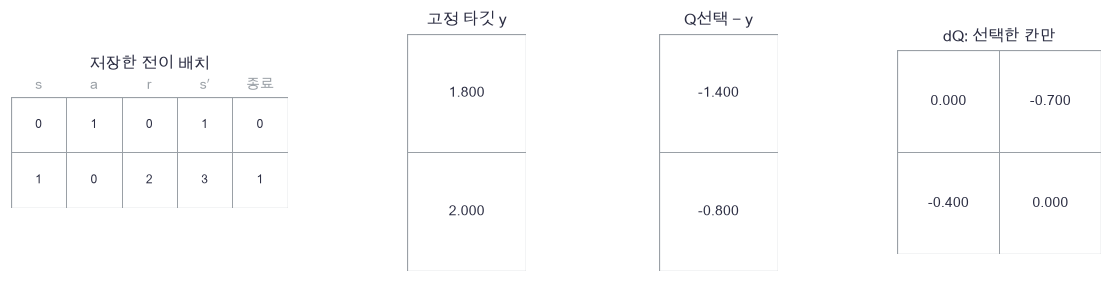

In [11]:
plot_td_batch(example_batch, batch_targets, batch_residual, batch_dq)

🔍 **확인** · dQ의 각 행에서 실제 선택한 칸만 남습니다. 출력에서의 이 희소한 미분이 공유 신경망 전체로 전파됩니다. 함수·수치 미분·입력 미분을 모두 확인한 뒤 실제 학습에 사용하겠습니다.

In [12]:
def q_backward(dq,cache,params):
    """dQ:(B,A)에서 4개 파라미터와 입력 X의 전체 기울기를 계산합니다."""
    x,hidden = cache
    dh = dq@params['W2'].T
    dz = dh*(1.0-hidden**2)
    gradients = {'W1':x.T@dz,'b1':dz.sum(axis=0),
                 'W2':hidden.T@dq,'b2':dq.sum(axis=0)}
    return gradients,dz@params['W1'].T

In [13]:
def dqn_batch_loss(params,x,actions,targets):
    """고정 targets:(B,)의 제곱 TD loss=mean((Q선택−y)^2)/2와 semi-gradient를 반환합니다."""
    # 쓰는 것: q_forward (위 절의 정의·실행 셀)
    q,cache = q_forward(x,params)
    rows = np.arange(len(x))
    residual = q[rows,actions]-targets
    loss = 0.5*np.mean(residual**2)
    dq = np.zeros_like(q)
    dq[rows,actions] = residual/len(x)
    gradients,dx = q_backward(dq,cache,params)
    return float(loss),gradients,dx

In [14]:
def numerical_dqn_check(params,x,actions,targets,step=1e-5):
    """같은 고정 타깃에서 모든 파라미터 원소와 입력 원소의 중심차분을 비교합니다."""
    # 1. 학습되는 네 배열의 원소를 하나씩만 움직입니다.
    loss,analytic,dx = dqn_batch_loss(params,x,actions,targets)
    errors = {}
    for name,values in params.items():
        numeric = np.zeros_like(values)
        for index in np.ndindex(values.shape):
            original = values[index]
            values[index] = original+step
            plus = dqn_batch_loss(params,x,actions,targets)[0]
            values[index] = original-step
            minus = dqn_batch_loss(params,x,actions,targets)[0]
            values[index] = original
            numeric[index] = (plus-minus)/(2*step)
        errors[name] = np.max(np.abs(numeric-analytic[name]))
    # 2. 입력도 같은 손실에 대해 미분합니다. one-hot 밖 미소 변화는 미분 검산용입니다.
    numeric_x = np.zeros_like(x)
    for index in np.ndindex(x.shape):
        original = x[index]
        x[index] = original+step
        plus = dqn_batch_loss(params,x,actions,targets)[0]
        x[index] = original-step
        minus = dqn_batch_loss(params,x,actions,targets)[0]
        x[index] = original
        numeric_x[index] = (plus-minus)/(2*step)
    errors['X'] = np.max(np.abs(numeric_x-dx))
    return errors

In [15]:
def replay_add(buffer,position,transition,capacity):
    """최대 capacity개의 (s,a,r,s',terminated)를 환형 목록에 저장하고 다음 위치를 반환합니다."""
    if len(buffer)<capacity:
        buffer.append(transition)
    else:
        buffer[position] = transition
    return (position+1)%capacity

In [16]:
def replay_sample(buffer,batch_size,rng):
    """현재 buffer에서 균등·복원 추출합니다. 같은 전이가 한 배치에 여러 번 나올 수 있습니다."""
    indices = rng.integers(0,len(buffer),size=batch_size)
    batch = np.array([buffer[index] for index in indices])
    x = np.eye(4)[batch[:,0].astype(int)]
    actions = batch[:,1].astype(int)
    rewards = batch[:,2]
    next_x = np.eye(4)[batch[:,3].astype(int)]
    terminated = batch[:,4].astype(bool)
    return x,actions,rewards,next_x,terminated

In [17]:
# 쓰는 것: dqn_batch_loss, init_q_network (위 절의 정의·실행 셀)
gradient_rng = np.random.default_rng(55001)
gradient_params = init_q_network(gradient_rng,3,3,2)
gradient_x = gradient_rng.normal(size=(2,3))
gradient_actions,gradient_targets = np.array([0,1]),np.array([.4,-.7])
gradient_errors = numerical_dqn_check(gradient_params,gradient_x,gradient_actions,gradient_targets)
assert max(gradient_errors.values())<1e-7, '네 파라미터와 입력의 전체 중심차분이 일치해야 합니다'
print('모든 파라미터·입력 중심차분 최대오차:',gradient_errors)
loss,gradients,dx = dqn_batch_loss(gradient_params,gradient_x,gradient_actions,gradient_targets)
loss_twice,grads_twice,dx_twice = dqn_batch_loss(gradient_params,np.tile(gradient_x,(2,1)),np.tile(gradient_actions,2),np.tile(gradient_targets,2))
np.testing.assert_allclose(loss_twice,loss)  # 검산: 같은 배치를 두 번 복제해도 평균 손실 불변
for name in gradients:
    np.testing.assert_allclose(grads_twice[name],gradients[name])  # 검산: 배치 평균 파라미터 미분의 분모
print('평균 손실·파라미터 미분의 배치 복제 검산 통과')

모든 파라미터·입력 중심차분 최대오차: {'W1': np.float64(5.798611590890346e-12), 'b1': np.float64(2.0869833639025615e-12), 'W2': np.float64(3.3364561113913282e-12), 'b2': np.float64(4.850009283074996e-12), 'X': np.float64(3.393632597159524e-12)}
평균 손실·파라미터 미분의 배치 복제 검산 통과


In [18]:
toy_buffer,position = [],0
for index in range(5):
    position = replay_add(toy_buffer,position,(0,0,float(index),2,False),3)
assert sorted(item[2] for item in toy_buffer)==[2.,3.,4.], '용량3에는 최근3전이가 남아야 합니다'
sample_x,sample_actions,sample_rewards,sample_next,sample_terminal = replay_sample(toy_buffer,6,np.random.default_rng(55002))
assert sample_x.shape==(6,4), '상태는6개 one-hot 행으로 반환해야 합니다'
assert np.isin(sample_rewards,[2.,3.,4.]).all(), '배치 보상은 실제 저장 전이에서만 나와야 합니다'
np.testing.assert_allclose(sample_x.sum(axis=1),1.0)  # 검산: 모든 입력 행이 one-hot
print('환형 덮어쓰기·replay 실제 저장값·배치 모양 통과')

환형 덮어쓰기·replay 실제 저장값·배치 모양 통과


### ✏️ 연습 2 · 선택 출력의 미분

residual=예측−타깃을 B로 나눠 dQ의 선택 칸에 넣으세요.

In [19]:
def exercise_dq(residual, actions, action_count):
    """선택 출력의 미분의 핵심 식을 완성합니다."""
    dq = np.zeros((len(residual),action_count))
    raise NotImplementedError
    return dq

In [20]:
def check_dq(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([-1.4,-.8]),np.array([1,0]),2),[[0.,-.7],[-.4,0.]])  # 검산:선택칸만배치평균미분
    print('선택 출력 미분 통과')

run_check(check_dq,exercise_dq,hint='선택하지 않은 칸은0입니다.')

☐ exercise_dq: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 선택하지 않은 칸은0입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dq[np.arange(len(residual)), actions] = residual / len(residual)
```

</details>

## 🔑 3. target은 optimizer 대신 정한 시점에 복사합니다

**이 절에서 가져갈 것:** online 업데이트와 target 동기화는 다른 연산이며, 참조 공유 없이 복사합니다.

현재 Q를 갱신할 때마다 목표까지 함께 움직이면 회귀 문제가 계속 바뀝니다. 별도 복사본 θ̄를 만들고 C번의 optimizer 갱신마다 θ̄←θ로 바꿉니다.

> **용어**
>
> - **target network θ̄**는 다음 상태의 목표 값을 만드는 별도 파라미터 복사본입니다.
> - **hard update**는 정한 시점에 target의 모든 파라미터를 online 값으로 복사하는 방식입니다.
> - **stop-gradient**는 타깃을 숫자로 취급해 현재 손실의 미분 경로에서 제외하는 규약입니다. NumPy 구현에서는 타깃 가지에 backward를 호출하지 않습니다.

$$y_i=r_i+\gamma(1-terminated_i)\max_aQ_{\bar\theta}(s'_i,a).$$

진짜 종료에서는 다음 Q를 막습니다. 수집 제한이라면 아직 종료하지 않았으므로 다음 Q를 남깁니다. 학습 주기의 C는 환경 episode가 아니라 **optimizer 업데이트 횟수**로 셉니다. 아래는 C=3의 스칼라 복사 예시입니다. 현재 모델도 같은 숫자가 되라는 학습 결과가 아니라 복사 규약을 보는 그림입니다.

> **코드** · `{name:value.copy() for ...}`는 각 배열의 독립 복사본을 만듭니다. `target=params`는 같은 객체를 가리키므로 고정 타깃이 아닙니다. `np.shares_memory`로 배열 공유를 검사합니다. `updates % C == 0`은 C번마다 복사하는 조건입니다.

In [21]:
copy_steps = np.arange(1,8)
online_values = copy_steps.copy()
target_values = np.zeros(7)
copy_flags = (copy_steps%3==0).astype(int)
current_target = 0
for index,step in enumerate(copy_steps):
    if step%3==0:
        current_target = online_values[index]
    target_values[index] = current_target

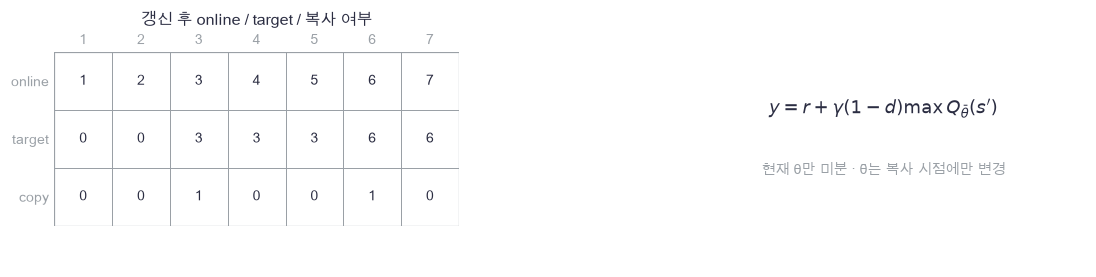

In [22]:
plot_target_freeze(copy_steps, online_values, target_values, copy_flags)

🔍 **확인** · online은 매번 변하지만 target은3·6번째 갱신 직후에만 바뀝니다. C=1이어도 한 손실을 미분하는 동안 타깃은 고정하며, 매 optimizer 갱신 **뒤** 복사한다는 순서를 지킵니다. 오래 고정하면 값이 낡을 수도 있으므로 C가 클수록 무조건 좋다는 규칙은 없습니다.

In [23]:
def copy_q_parameters(params):
    """각 배열을 복사해 online과 메모리를 공유하지 않는 target 네트워크를 만듭니다."""
    return {name:value.copy() for name,value in params.items()}

In [24]:
def make_dqn_targets(rewards,terminated,next_online,next_target,gamma,double=False):
    """다음 Q:(B,A)에서 DQN 또는 Double 타깃:(B,)을 만듭니다. backward 경로는 만들지 않습니다."""
    if double:
        actions = np.argmax(next_online,axis=1)
        continuation = next_target[np.arange(len(rewards)),actions]
    else:
        continuation = np.max(next_target,axis=1)
    return rewards+gamma*(1-terminated.astype(float))*continuation

In [25]:
def init_q_adam(params):
    """online 파라미터만의 Adam 1·2차 모멘트와 업데이트 번호를 초기화합니다."""
    return {'m':{name:np.zeros_like(value) for name,value in params.items()},
            'v':{name:np.zeros_like(value) for name,value in params.items()},'t':0}

In [26]:
def q_adam_step(params,gradients,state,learning_rate=0.005):
    """Adam 편향 보정 뒤 online 파라미터를 제자리 갱신합니다. target은 인자로 받지 않습니다."""
    state['t'] += 1
    for name in params:
        state['m'][name] = 0.9*state['m'][name]+0.1*gradients[name]
        state['v'][name] = 0.999*state['v'][name]+0.001*gradients[name]**2
        m_hat = state['m'][name]/(1-0.9**state['t'])
        v_hat = state['v'][name]/(1-0.999**state['t'])
        params[name] -= learning_rate*m_hat/(np.sqrt(v_hat)+1e-8)

In [27]:
# 쓰는 것: copy_q_parameters, gradient_params, gradients, target_values (위 절의 정의·실행 셀)
online_params = copy_q_parameters(gradient_params)
target_params = copy_q_parameters(online_params)
target_before = copy_q_parameters(target_params)
optimizer_state = init_q_adam(online_params)
q_adam_step(online_params,gradients,optimizer_state)
for name in online_params:
    np.testing.assert_array_equal(target_params[name],target_before[name])  # 검산: online optimizer는target을갱신하지않음
    assert not np.shares_memory(online_params[name],target_params[name]), 'online과target 배열은 독립 복사본이어야 합니다'
    expected = gradient_params[name]-.005*gradients[name]/(np.abs(gradients[name])+1e-8)
    np.testing.assert_allclose(online_params[name],expected,atol=1e-12)  # 검산: 첫 Adam은 편향보정 후 g/(|g|+eps)
np.testing.assert_allclose(target_values,[0,0,3,3,3,6,6])  # 검산: C3 복사 시점
boundary = make_dqn_targets(np.array([2.,0.]),np.array([True,False]),np.array([[99.,99.],[2.,-14.]]),np.array([[99.,99.],[2.,-14.]]),.9)
np.testing.assert_allclose(boundary,[2.,1.8])  # 검산: 종료99차단·비종료수집끝bootstrap
print('target 불변·메모리분리·Adam 첫 갱신·경계 통과')

target 불변·메모리분리·Adam 첫 갱신·경계 통과


### ✏️ 연습 3 · 종료 마스크를 넣은 DQN 타깃

target Q의 행동 최대를 쓰고 진짜 종료만 막으세요.

In [28]:
def exercise_target(rewards, terminated, next_q, gamma):
    """종료 마스크를 넣은 DQN 타깃의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return targets

In [29]:
def check_target(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([2.,0.]),np.array([True,False]),np.array([[99.,99.],[1.,2.]]),.9),[2.,1.8])  # 검산:종료와비종료분리
    print('DQN 종료 타깃 통과')

run_check(check_target,exercise_target,hint='수집 제한은 terminated=True로 바꾸지 않습니다.')

☐ exercise_target: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 수집 제한은 terminated=True로 바꾸지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
targets = rewards + gamma * (1 - terminated.astype(float)) * np.max(next_q, axis=1)
```

</details>

## 🔑 4. Double DQN은 선택과 평가를 나눕니다

**이 절에서 가져갈 것:** online에서 최대 행동을 고른 뒤, 그 행동의 target 값을 읽습니다.

다음 상태에서 online이 `(3,2)`를 예측하고 target이 `(1,4)`를 예측한다고 합시다. DQN은 target 최대4를 쓰지만 Double은 online 최대 행동0을 골라 target의1을 사용합니다.

> **용어** · **Double DQN**은 다음 행동의 선택과 값 평가를 두 네트워크로 나눈 DQN 변형입니다. 두 추정치의 오류가 실제로 독립이라는 보장은 없습니다.

$$a_i^*=\arg\max_aQ_\theta(s'_i,a),\qquad
y_i^{Double}=r_i+\gamma(1-terminated_i)Q_{\bar\theta}(s'_i,a_i^*).$$

argmax는 동점일 때 첫 행동을 고릅니다. 이번 단원의 데이터 수집 정책은 동점을 균등 분배하지만, Double 타깃의 동점 규약은 첫 행동으로 고정합니다. 이산 선택과 target 가지에는 backward를 하지 않습니다. 다음 행동을 선택하는 θ가 있다고 해서 y까지 미분하는 손실로 바꾸지 않습니다.

> **코드** · `np.argmax(Q,axis=1)`은 각 행의 최대 행동 번호입니다. 이 번호로 다른 배열인 target Q의 같은 행·같은 행동을 읽습니다. `np.tile`은 배열을 정한 횟수 복제합니다.

> **코드** · `np.column_stack([a,b])`는 DQN과 Double의 결과를 두 열로 붙입니다.

In [30]:
selection_online = np.array([[3.0,2.0],[5.0,1.0]])
selection_target = np.array([[1.0,4.0],[7.0,9.0]])
selection_rewards = np.array([0.0,2.0])
selection_terminal = np.array([False,True])
chosen_actions = np.argmax(selection_online,axis=1)
direct_double = selection_rewards+.9*(1-selection_terminal)*selection_target[np.arange(2),chosen_actions]
direct_dqn = selection_rewards+.9*(1-selection_terminal)*selection_target.max(axis=1)

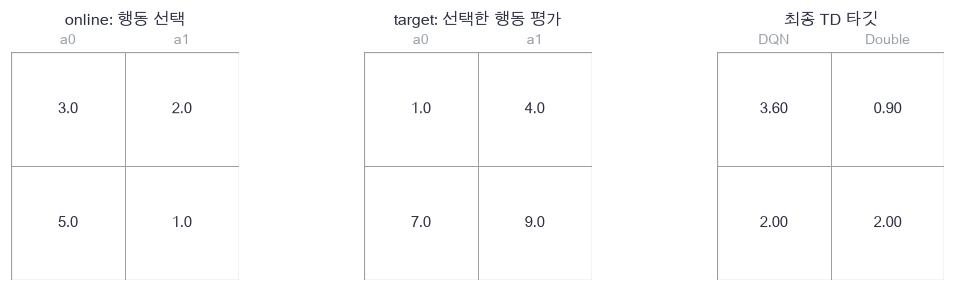

In [31]:
plot_double_selection(selection_online, selection_target, np.column_stack([direct_dqn,direct_double]))

🔍 **확인** · 첫 행의 타깃은 DQN3.6·Double.9입니다. 둘째 행은 종료라서 둘 다 보상2입니다. 서로 다른 숫자가 나온다는 사실만으로 어느 쪽이 실제 최적 Q에 가까운지 알 수는 없습니다. 다음 작은 잡음 예제는 최대 선택 편향만 분리해서 봅니다.

In [32]:
# 쓰는 것: make_dqn_targets (위 절의 정의·실행 셀)
np.testing.assert_allclose(make_dqn_targets(selection_rewards,selection_terminal,selection_online,selection_target,.9,True),[.9,2.])  # 검산:online선택·target평가·종료마스크
np.testing.assert_allclose(make_dqn_targets(selection_rewards,selection_terminal,selection_online,selection_target,.9,False),[3.6,2.])  # 검산:DQN은target최대
noise_pairs = np.array([[-1.,-1.],[-1.,1.],[1.,-1.],[1.,1.]])
max_noise = np.max(noise_pairs,axis=1)
independent_evaluations = []
correlated_evaluations = []
for selection in noise_pairs:
    action = np.argmax(selection)
    correlated_evaluations.append(selection[action])
    for evaluation in noise_pairs:
        independent_evaluations.append(evaluation[action])
np.testing.assert_allclose(max_noise.mean(),.5)  # 검산:평균0잡음둘중최대의4경우기대값.5
np.testing.assert_allclose(np.mean(independent_evaluations),0.)  # 검산:독립평가의16경우정확기대0
np.testing.assert_allclose(np.mean(correlated_evaluations),.5)  # 검산:선택과같은잡음을평가하면편향유지
print('선택/평가 분리 통과 · 독립 잡음 통제0, 완전 상관 통제.5')

선택/평가 분리 통과 · 독립 잡음 통제0, 완전 상관 통제.5


### ✏️ 연습 4 · Double의 평가 값을 고릅니다

online에서 고른 행동을 target에서 평가하세요.

In [33]:
def exercise_double(online, target):
    """Double의 평가 값을 고릅니다의 핵심 식을 완성합니다."""
    actions = np.argmax(online,axis=1)
    raise NotImplementedError
    return values

In [34]:
def check_double(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([[3.,2.]]),np.array([[1.,4.]])),[1.])  # 검산:online0선택후target0읽기
    print('Double 선택·평가 통과')

run_check(check_double,exercise_double,hint='target에서 다시 argmax하면 DQN과 같아집니다.')

☐ exercise_double: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: target에서 다시 argmax하면 DQN과 같아집니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
values = target[np.arange(len(target)), actions]
```

</details>

## 🔑 5. 실제 replay 학습을 정확한 작은 환경과 대조합니다

**이 절에서 가져갈 것:** 상호작용·배치·복사 예산을 고정하고 실제 학습된 Q와 정책을 평가합니다.

같은 환경에서 DQN C=1, DQN C=50, Double C=50을 각각3개 독립 seed로 학습합니다. 각 실행은1,200개 episode·2,400개 전이입니다. 초기화·행동·replay 난수 스트림은 분리합니다. 같은 seed에서는 초기 네트워크가 같고, 정책이 달라지면 수집 경로도 달라질 수 있습니다.

ε는1에서 시작해600개 episode 동안 .1까지 선형으로 줄이고 이후 유지합니다. replay 용량256·배치32·Adam 학습률.005를 사전 고정합니다. 32개 전이를 모은 뒤 매 전이마다 한 optimizer 갱신을 하므로 총2,369번입니다. target 복사는 optimizer 갱신 **뒤** C번마다입니다.

평가에는 알려진 정확해 $Q^*_{s<3}=((.63,1.8),(2,-14),(.7,.7))$를 씁니다. 학습 업데이트에는 이 정확해를 넣지 않습니다. Q RMSE는 **비종료6칸** 평균입니다. 종료 상태 출력은 직접 학습하지 않아0이 아닐 수 있지만 타깃 마스크로 사용을 막습니다. 별도2,000개 경로로 탐색 ε=.1을 유지한 동결 정책의 평가 평균·SE도 확인합니다.

> **용어** · **평가의 두 대상**: Q RMSE는 값 추정 오차이고, greedy 정책 가치는 그 값으로 행동을 골랐을 때의 실제 기대 return입니다. 같은 행동 순위를 내는 다른 Q들도 같은 정책 가치를 가질 수 있습니다.

> **코드** · `zip(names,settings)`는 같은 위치의 이름·설정을 함께 순회합니다. `np.stack`은 새 축으로 기록을 쌓습니다. 아래 학습 루프의 `loss,gradients,dx` 중 갱신에 쓰이는 것은 gradients이며 loss와 dx는 이 루프에서 추가 사용하지 않습니다.

In [35]:
REPEATS,EPISODES,CHECKPOINT = 3,1200,50
parameter_count = 4*16+16+16*2+2
protocol_settings = np.array([[REPEATS],[EPISODES],[256],[32],[.005],[parameter_count]])
protocol_counts = np.array([[1,1,0],[31,31,0],[32,32,1],[2400,256,2369]])

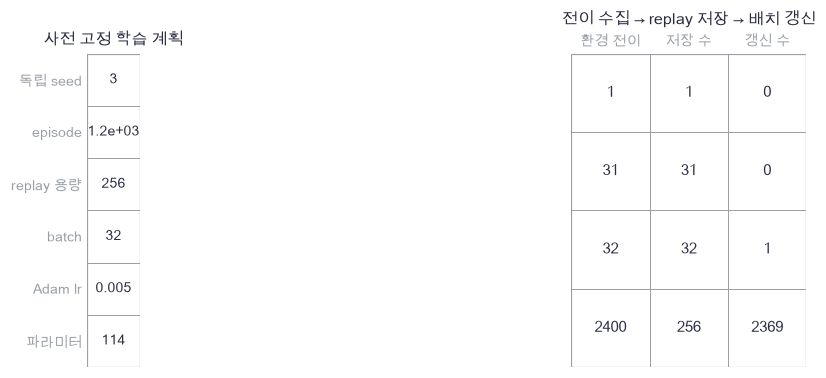

In [36]:
plot_dqn_protocol(protocol_settings, protocol_counts)

🔍 **확인** · 신경망 파라미터는114개이고 replay에는 최대256개 전이만 남습니다. 환경 전이 수와 optimizer 갱신 수는 초기 수집 때문에 다릅니다. 이 작은 결정적 환경은 결국 표의6칸을 맞히기 쉬우므로, 안정화 장치의 일반적인 효과를 검증할 큰 벤치마크로 해석하지 않습니다.

In [37]:
def dqn_exact_value(q,epsilon=0.0,gamma=0.9):
    """이 환경에서 동결 ε-greedy Q 정책의 정확 시작 가치를 손계산과 같은 두 단계로 구합니다."""
    greedy = (q==q.max(axis=1,keepdims=True)).astype(float)
    greedy /= greedy.sum(axis=1,keepdims=True)
    policy = epsilon/2+(1-epsilon)*greedy
    risky = 2*policy[1,0]-14*policy[1,1]
    safe = 0.7
    return float(gamma*(policy[0,0]*safe+policy[0,1]*risky))

In [38]:
def train_dqn(seed,double=False,sync_interval=50,episodes=1200,checkpoint=100):
    """실제 환경·replay·online backward·target copy 전체 학습. 반환 params·기록·return·동기화 번호."""
    # 쓰는 것: copy_q_parameters, dqn_batch_loss, init_q_adam, init_q_network, make_dqn_environment, make_dqn_targets, q_adam_step, q_forward, replay_add, replay_sample (위 절의 정의·실행 셀)
    # 1. 초기화·행동·replay 난수 스트림을 분리하고 실험 예산을 고정합니다.
    next_state,reward,terminal = make_dqn_environment()
    params = init_q_network(np.random.default_rng(seed))
    target = copy_q_parameters(params)
    adam = init_q_adam(params)
    action_rng,replay_rng = np.random.default_rng(seed+10000),np.random.default_rng(seed+20000)
    buffer,position,updates = [],0,0
    records,sync_steps = [],[]
    returns = np.zeros(episodes)
    features = np.eye(4)
    # 2. 2전이 경로를 수집하고, 32전이 이후 매 전이마다 한 배치를 학습합니다.
    for episode in range(episodes):
        state = 0
        epsilon = max(0.1,1.0-0.9*episode/600)
        for step in range(2):
            q = q_forward(features[state:state+1],params)[0][0]
            greedy = (q==q.max()).astype(float)
            probabilities = epsilon/2+(1-epsilon)*greedy/greedy.sum()
            action = int(np.searchsorted(np.cumsum(probabilities),action_rng.random(),side='right'))
            destination = int(next_state[state,action])
            observed_reward = float(reward[state,action])
            position = replay_add(buffer,position,(state,action,observed_reward,destination,terminal[destination]),256)
            returns[episode] += 0.9**step*observed_reward
            if len(buffer)>=32:
                x,actions,rewards,next_x,terminated = replay_sample(buffer,32,replay_rng)
                next_online = q_forward(next_x,params)[0]
                next_target = q_forward(next_x,target)[0]
                targets = make_dqn_targets(rewards,terminated,next_online,next_target,0.9,double)
                loss,gradients,dx = dqn_batch_loss(params,x,actions,targets)
                q_adam_step(params,gradients,adam)
                updates += 1
                if updates%sync_interval==0:
                    target = copy_q_parameters(params)
                    sync_steps.append(updates)
            state = destination
        # 3. 정확 환경 평가는 기록만 하며 replay나 optimizer로 돌려보내지 않습니다.
        if (episode+1)%checkpoint==0:
            online_q = q_forward(features,params)[0]
            target_q = q_forward(features,target)[0]
            records.append((online_q.copy(),target_q.copy(),updates))
    return params,records,returns,np.array(sync_steps)

In [39]:
# 쓰는 것: init_q_network, parameter_count (위 절의 정의·실행 셀)
q_truth = np.array([[.63,1.8],[2.,-14.],[.7,.7],[0.,0.]])
np.testing.assert_allclose(dqn_exact_value(q_truth),1.8)  # 검산:greedy는위험경로에서좋은행동→.9×2
np.testing.assert_allclose(dqn_exact_value(q_truth,.1),1.0575)  # 검산:.9×(.05×.7+.95×(.95×2+.05×−14))
initial_params = init_q_network(np.random.default_rng(55100))
assert sum(value.size for value in initial_params.values())==parameter_count, '실제 파라미터 합은114여야 합니다'
print('정확 정책 가치·실제 파라미터 수 통과:',parameter_count)

정확 정책 가치·실제 파라미터 수 통과: 114


In [40]:
# 쓰는 것: CHECKPOINT, EPISODES, REPEATS (위 절의 정의·실행 셀)
names = ['DQN C=1','DQN C=50','Double C=50']
settings = [(False,1),(False,50),(True,50)]
episode_axis = np.arange(CHECKPOINT,EPISODES+1,CHECKPOINT)
q_records = np.zeros((3,REPEATS,len(episode_axis),4,2))
target_records = np.zeros_like(q_records)
training_returns = np.zeros((3,REPEATS))
sync_counts = np.zeros((3,REPEATS),dtype=int)
for method,(double,interval) in enumerate(settings):
    for repeat in range(REPEATS):
        params,records,returns,sync_steps = train_dqn(55100+repeat,double,interval,EPISODES,CHECKPOINT)
        q_records[method,repeat] = np.stack([record[0] for record in records])
        target_records[method,repeat] = np.stack([record[1] for record in records])
        training_returns[method,repeat] = returns.mean()
        sync_counts[method,repeat] = len(sync_steps)
        np.testing.assert_array_equal(sync_steps,np.arange(interval,2370,interval))  # 검산:실제복사번호=업데이트C배수
        assert records[-1][2]==2369, '실제 optimizer 예산은2369회여야 합니다'
print('3설정×3seed 학습 완료 · 동기화 횟수:',sync_counts[:,0])

3설정×3seed 학습 완료 · 동기화 횟수: [2369   47   47]


In [41]:
# 쓰는 것: REPEATS, dqn_exact_value (위 절의 정의·실행 셀)
q_rmse = np.sqrt(np.mean((q_records[:,:,:,:3,:]-q_truth[:3])**2,axis=(3,4)))
target_gap = np.sqrt(np.mean((q_records[:,:,:,:3,:]-target_records[:,:,:,:3,:])**2,axis=(3,4)))
policy_values = np.zeros((3,REPEATS,len(episode_axis)))
for method in range(3):
    for repeat in range(REPEATS):
        for index in range(len(episode_axis)):
            policy_values[method,repeat,index] = dqn_exact_value(q_records[method,repeat,index])
mean_rmse,mean_values,mean_gap = q_rmse.mean(axis=1),policy_values.mean(axis=1),target_gap.mean(axis=1)
final_mean_q = q_records[:,:,-1,:3,:].mean(axis=1).reshape(3,6)

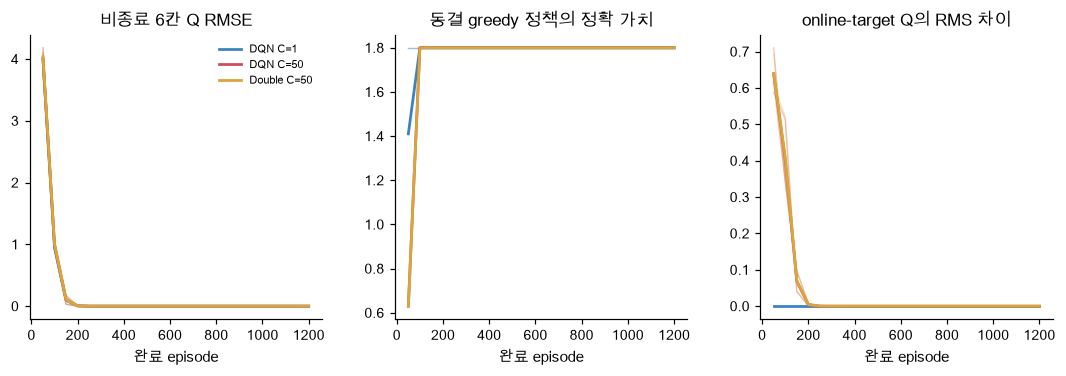

In [42]:
plot_dqn_learning(episode_axis, q_rmse, policy_values, target_gap, mean_rmse, mean_values, mean_gap, names)

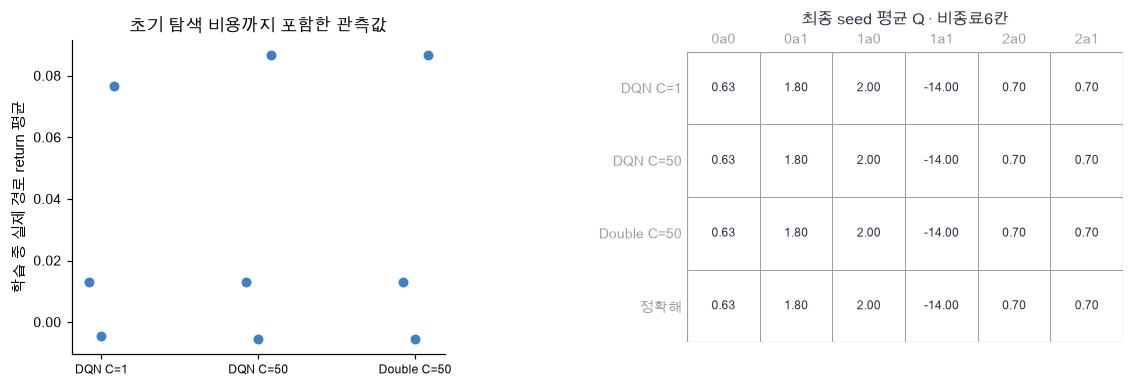

In [43]:
plot_dqn_final(names, training_returns, final_mean_q, q_truth[:3].reshape(6))

🔍 **확인** · 얇은 선은 각각의 독립 학습 seed, 굵은 선은3개 평균입니다. 표본이 적으므로 좁은 신뢰구간을 주장하지 않습니다. 세 설정의 최종 정책이 같게 나와도 실제 학습 결과를 그대로 남깁니다. Double의 선택 편향 통제 예제와 이 작은 환경의 유한 학습 성과는 별개의 근거입니다. 학습 중 평균 return은 초반 큰 탐색 비용을 포함하므로 최종 동결 정책 가치보다 낮을 수 있습니다.

In [44]:
# 쓰는 것: dqn_exact_value, names, next_state, q_records, reward (위 절의 정의·실행 셀)
evaluation_uniforms = np.random.default_rng(55999).random((2000,2))
for method,name in enumerate(names):
    frozen_q = q_records[method,0,-1]
    greedy = (frozen_q==frozen_q.max(axis=1,keepdims=True)).astype(float)
    policy = .1/2+.9*greedy/greedy.sum(axis=1,keepdims=True)
    evaluation_returns = np.zeros(2000)
    for episode in range(2000):
        state = 0
        for step in range(2):
            action = np.searchsorted(np.cumsum(policy[state]),evaluation_uniforms[episode,step],side='right')
            evaluation_returns[episode] += .9**step*reward[state,action]
            state = next_state[state,action]
    print(name,'각seed 최종 Q RMSE:',q_rmse[method,:,-1],'greedy 가치:',policy_values[method,:,-1])
    print('첫seed 독립ε=.1평가 평균/SE/정확값:',round(evaluation_returns.mean(),4),round(evaluation_returns.std(ddof=1)/np.sqrt(2000),4),dqn_exact_value(frozen_q,.1))
assert np.isfinite(q_records).all(), '학습된 모든 Q는유한해야 합니다'
print('유한값·복사주기 검산 통과 · 성능 우열은 assert하지 않습니다')

DQN C=1 각seed 최종 Q RMSE: [1.13054834e-14 8.68295673e-16 1.11022302e-16] greedy 가치: [1.8 1.8 1.8]
첫seed 독립ε=.1평가 평균/SE/정확값: 1.0474 0.0688 1.0575000000000003
DQN C=50 각seed 최종 Q RMSE: [1.20561053e-14 3.63333101e-15 6.57754440e-15] greedy 가치: [1.8 1.8 1.8]
첫seed 독립ε=.1평가 평균/SE/정확값: 1.0474 0.0688 1.0575000000000003
Double C=50 각seed 최종 Q RMSE: [3.18780943e-13 3.65025393e-15 3.62738933e-15] greedy 가치: [1.8 1.8 1.8]
첫seed 독립ε=.1평가 평균/SE/정확값: 1.0474 0.0688 1.0575000000000003
유한값·복사주기 검산 통과 · 성능 우열은 assert하지 않습니다


### ✏️ 연습 5 · 학습 예산을 셉니다

환경 전이 T개 중 처음 B개째부터 매번 한 번 갱신합니다.

In [45]:
def exercise_budget(transitions, batch_size):
    """학습 예산을 셉니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return updates

In [46]:
def check_budget(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    assert fn(2400,32)==2369, '32번째부터2400번째까지2369번입니다'
    print('환경 전이와optimizer 예산 통과')

run_check(check_budget,exercise_budget,hint='초기 batch_size−1개에서는 갱신하지 않습니다.')

☐ exercise_budget: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 초기 batch_size−1개에서는 갱신하지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
updates = max(0, transitions - batch_size + 1)
```

</details>

## ✏️ 전체 연결 연습 A–D

배치 평균·복사·행동 선택·평가 축을 연결합니다.

### ✏️ 연습 A · 제곱 TD 손실

1/2와 배치 평균을 포함해 계산하세요.

In [47]:
def exercise_loss(selected, targets):
    """제곱 TD 손실의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return loss

In [48]:
def check_loss(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.4,1.2]),np.array([1.8,2.])),.65)  # 검산:(1.96+.64)/4
    print('TD 손실 통과')

run_check(check_loss,exercise_loss,hint='합을 그대로 쓰면 배치 크기에 따라 스케일이 달라집니다.')

☐ exercise_loss: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 합을 그대로 쓰면 배치 크기에 따라 스케일이 달라집니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = 0.5 * np.mean((selected - targets)**2)
```

</details>

### ✏️ 연습 B · 독립 target 배열

같은 메모리를 공유하지 않는 배열을 반환하세요.

In [49]:
def exercise_copy(online):
    """독립 target 배열의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return target

In [50]:
def check_copy(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    x=np.array([1.,2.])
    y=fn(x)
    x[0]=9.
    np.testing.assert_array_equal(y,[1.,2.])  # 검산:online갱신뒤target보존
    print('독립 배열 복사 통과')

run_check(check_copy,exercise_copy,hint='단순 대입은 복사하지 않습니다.')

☐ exercise_copy: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 단순 대입은 복사하지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
target = online.copy()
```

</details>

### ✏️ 연습 C · tanh 도함수

이미 계산한 hidden을 이용해 미분하세요.

In [51]:
def exercise_tanh(hidden):
    """tanh 도함수의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return derivative

In [52]:
def check_tanh(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([0.,.5])),[1.,.75])  # 검산:1−tanh출력제곱
    print('tanh 미분 통과')

run_check(check_tanh,exercise_tanh,hint='hidden은 preactivation이 아니라 tanh 출력입니다.')

☐ exercise_tanh: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: hidden은 preactivation이 아니라 tanh 출력입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
derivative = 1.0 - hidden**2
```

</details>

### ✏️ 연습 D · 비종료 Q RMSE

여기 받은 두 배열은 이미 비종료 칸만 잘랐습니다.

In [53]:
def exercise_rmse(predicted, truth):
    """비종료 Q RMSE의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return rmse

In [54]:
def check_rmse(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([[0.,2.]]),np.array([[1.,1.]])),1.)  # 검산:두칸제곱오차평균1의제곱근
    print('Q RMSE 통과')

run_check(check_rmse,exercise_rmse,hint='행동·상태 모든 칸의 평균입니다.')

☐ exercise_rmse: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 행동·상태 모든 칸의 평균입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
rmse = np.sqrt(np.mean((predicted - truth)**2))
```

</details>

## ✏️ 준비도: 네 가지로 확인합니다

- **설명:** replay·target network·Double이 각각 데이터 재사용·타깃 시점·행동 선택/평가 중 무엇을 바꾸는지 말할 수 있나요?
- **수식:** 선택한 Q의 제곱 손실부터 네 파라미터와 X의 미분을 shape에 맞게 전개할 수 있나요?
- **구현:** 고정 타깃을 그대로 둔 중심차분과 target 배열 불변 검사를 구현할 수 있나요?
- **변형 검산:** C=1·다른 배치 크기·진짜 종료·수집 제한에서 타깃과 실제 optimizer 예산이 어떻게 바뀌는지 확인할 수 있나요?

## 📎 참고: 원자료와 다음 연결

- Mnih 외, [Human-level control through deep reinforcement learning](https://deepmind-media.storage.googleapis.com/dqn/DQNNaturePaper.pdf): replay와 주기적인 target 복사를 사용하는 DQN 원자료입니다. 이 노트북은 one-hot MLP·제곱 손실·Adam의 작은 교육 실험입니다.
- van Hasselt 외, [Deep Reinforcement Learning with Double Q-learning](https://arxiv.org/abs/1509.06461): online 선택과 target 평가를 나누는 Double DQN의 근거입니다. 본문의 독립 잡음 전수열거는 그 원리를 분리한 별도 통제 예제입니다.
- 다음 56번은 Q의 최대 행동을 고르는 대신 행동 확률 자체를 보상으로 미분합니다. [전체 경로](../../docs/CURRICULUM.md)에서 정책 기울기로 이어집니다.